# Ingresos: conciliación, periodicidad y contaminación

## Resumen de la ejecución

Datos sintéticos; resultados de esta ejecución:

- **Abonos brutos (COP):** 10000000
- **Ingreso elegible (COP):** 3000000
- **Sobreestimación por sumar abonos:** 3.333
- **Conversiones reconciliadas:** 5
- **Ingreso conciliado por eventos (COP):** 3000000
- **Cambio de saldo consolidado (COP):** 7000000
- **Duplicado contradictorio rechazado:** True

Los supuestos, límites y contraejemplos se explican junto a cada experimento.

## Objetivo y método

¿Una entrada de dinero representa ingreso disponible? Construimos un caso contable verificable, probamos conversiones de periodicidad y medimos sensibilidad de la normalización a contaminación.

### Supuestos y población

Un período mensual y una moneda. Las categorías de flujo se conocen por construcción. En producción requieren evidencia, reglas de conciliación y fuentes independientes; no se infiere intención del cliente.

Todos los datos son sintéticos. Las cifras ilustran mecanismos y no constituyen desempeño observado en una entidad. Fecha de desarrollo: 21 de octubre de 2026.

## Entorno reproducible

Ejecutar en orden, desde esta carpeta o una subcarpeta de la línea de fraude. La semilla y los parámetros quedan en las celdas; no se consulta internet ni se leen datos de clientes.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score, brier_score_loss
base = next(p for p in [Path.cwd(), *Path.cwd().parents] if p.name == 'fraud-and-anomaly-research')
sys.path.insert(0, str(base / 'loss-minimization-engine'))
from src.engine import Case, Action, Scenario, optimize, expected_cost, shared_entity_count
rng = np.random.default_rng(20261021)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False, 'grid.alpha': .25})
BLUE, TEAL, GOLD, PURPLE = '#386A96', '#217A72', '#B37D2E', '#73579D'
pd.options.display.float_format = '{:,.4f}'.format

No event loop hook running.


## 1. Conciliar antes de modelar


$$I_{mes}=\sum_{j\in\mathrm{ingresos\ elegibles}}F_j,\quad \mathrm{abonos\ brutos}=I_{mes}+\mathrm{traslados}+\mathrm{créditos}+\mathrm{otros}.$$

Una transferencia entre cuentas propias y un desembolso de préstamo no son ingreso laboral. Sumar ambos al ingreso puede crear capacidad de pago ficticia.

,tipo,monto_COP,elegible_ingreso
0,salario,1500000,True
1,traslado propio,2000000,False
2,préstamo,5000000,False
3,salario,1500000,True


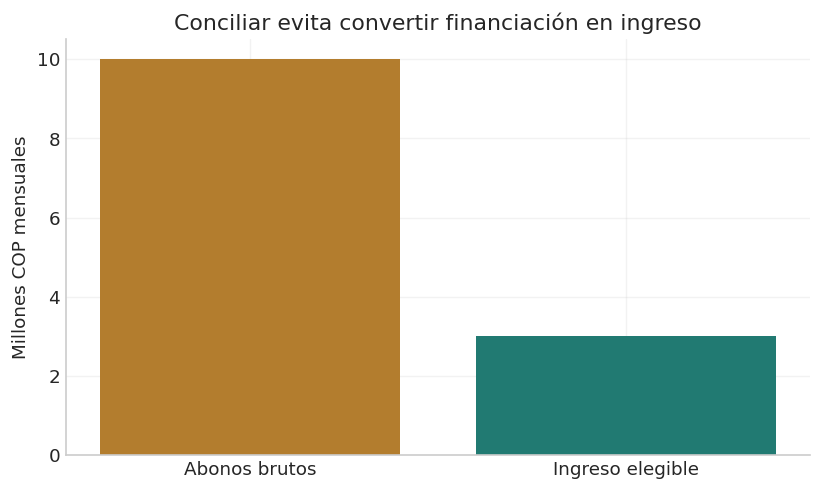

In [2]:
flows=pd.DataFrame({'tipo':['salario','traslado propio','préstamo','salario'],
                    'monto_COP':[1_500_000,2_000_000,5_000_000,1_500_000],
                    'elegible_ingreso':[True,False,False,True]})
gross=flows['monto_COP'].sum();eligible=flows.loc[flows['elegible_ingreso'],'monto_COP'].sum()
display(flows)
fig,ax=plt.subplots();ax.bar(['Abonos brutos','Ingreso elegible'],[gross/1e6,eligible/1e6],color=[GOLD,TEAL])
ax.set(ylabel='Millones COP mensuales',title='Conciliar evita convertir financiación en ingreso');plt.show()

El ejemplo expone un error de definición y no demuestra fraude. Una categoría mal etiquetada es un problema del contrato de datos antes de ser un problema del clasificador.

## 2. Periodicidad y pruebas dimensionales


$$I_{mensual}=I_{anual}/12=2I_{quincenal}=I_{semanal}\,52/12.$$

Quincenal se define aquí como dos pagos al mes, no cada 14 días. En este último caso el factor anualizado sería 26/12. Registrar la convención evita reconciliaciones falsas.

In [3]:
def monthly(amount,period):
    factors={'mensual':1.,'anual':1/12,'quincenal':2.,'semanal':52/12,'cada_14_días':26/12}
    if period not in factors or not np.isfinite(amount) or amount<0:raise ValueError('Monto/período inválido')
    return amount*factors[period]
conversions=pd.DataFrame({'periodo':['mensual','anual','quincenal','semanal','cada_14_días'],
                          'monto_COP':[3_000_000,36_000_000,1_500_000,3_000_000*12/52,3_000_000*12/26]})
conversions['mensual_COP']=[monthly(a,p) for a,p in zip(conversions['monto_COP'],conversions['periodo'])]
display(conversions)

,periodo,monto_COP,mensual_COP
0,mensual,"3,000,000.0000","3,000,000.0000"
1,anual,"36,000,000.0000","3,000,000.0000"
2,quincenal,"1,500,000.0000","3,000,000.0000"
3,semanal,"692,307.6923","3,000,000.0000"
4,cada_14_días,"1,384,615.3846","3,000,000.0000"


El redondeo debe aplicarse al presentar o según contrato, no antes de toda conversión. El mismo flujo observado no debe sumarse dos veces por estar en dos cuentas o dos extracciones.

## 3. Media y escala robusta ante contaminación


Para evidencia comparable de log ingreso, $z_{rob}=(x-\mathrm{mediana})/(1,4826\,MAD)$ y $MAD=\mathrm{mediana}|x-\mathrm{mediana}|$.

El factor 1,4826 aproxima la desviación normal cuando el supuesto es apropiado. La robustez de una estadística no verifica autenticidad de documentos ni justifica un umbral universal.

,contaminacion,metodo,alarma_legitimos,deteccion_desplazamiento,centro_log,escala_log
0,0.0000,media/desviación,0.0012,0.5550,14.9139,0.1879
1,0.0000,mediana/MAD,0.0012,0.5550,14.9161,0.1870
2,0.0500,media/desviación,0.0000,0.0000,15.0139,0.4762
3,0.0500,mediana/MAD,0.0000,0.3950,14.9301,0.2058
4,0.1000,media/desviación,0.0000,0.0000,15.1139,0.6350
5,0.1000,mediana/MAD,0.0000,0.2950,14.9381,0.2176
6,0.2000,media/desviación,0.0000,0.0000,15.3139,0.8274
7,0.2000,mediana/MAD,0.0000,0.1350,14.9663,0.2551
8,0.3500,media/desviación,0.0000,0.0000,15.6139,0.9773
9,0.3500,mediana/MAD,0.0000,0.0000,15.0415,0.4112


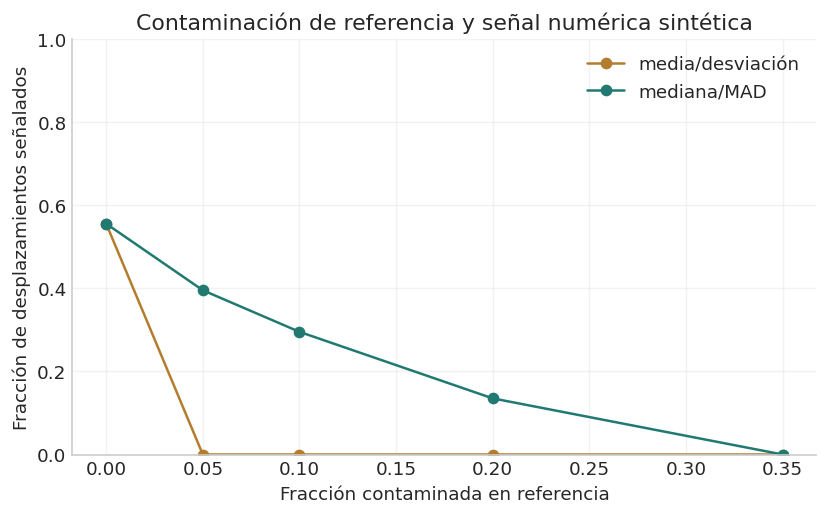

In [4]:
clean=rng.normal(np.log(3_000_000),.18,1000)
legitimate_test=rng.normal(np.log(3_000_000),.18,800)
shifted_test=rng.normal(np.log(3_000_000)+.6,.18,200)
records=[]
for contamination in [0,.05,.1,.2,.35]:
    mixed=clean.copy();count=int(contamination*len(mixed))
    mixed[:count]+=2.
    mean,sd=mixed.mean(),mixed.std(ddof=1)
    median=np.median(mixed);scale=1.4826*np.median(np.abs(mixed-median))
    for method,center,spread in [('media/desviación',mean,sd),('mediana/MAD',median,scale)]:
        # Threshold fixed before evaluation. Shifted examples are discrepancies,
        # not adjudicated fraud; 'detection' means a synthetic numeric shift.
        records.append({'contaminacion':contamination,'metodo':method,
                        'alarma_legitimos':np.mean((legitimate_test-center)/spread>3),
                        'deteccion_desplazamiento':np.mean((shifted_test-center)/spread>3),
                        'centro_log':center,'escala_log':spread})
robustness=pd.DataFrame(records);display(robustness.round(4))
fig,ax=plt.subplots()
for method,color in [('media/desviación',GOLD),('mediana/MAD',TEAL)]:
    subset=robustness[robustness['metodo']==method]
    ax.plot(subset['contaminacion'],subset['deteccion_desplazamiento'],marker='o',label=method,color=color)
ax.set(xlabel='Fracción contaminada en referencia',ylabel='Fracción de desplazamientos señalados',ylim=(0,1),title='Contaminación de referencia y señal numérica sintética');ax.legend();plt.show()

La curva evalúa un desplazamiento numérico, no fraude. El MAD también cambia con contaminación alta y con mezclas de actividades; segmentar y validar sigue siendo necesario. En caso de escala cero o población escasa se debe abstener o usar un fallback documentado.

## Desarrollo ampliado: modelo, estimación y uso


**Uso:** preparar evidencia económica consistente antes de estimar ingreso o capacidad de pago. **Entrada:** eventos con ID, titularidad, categoría, signo, moneda, período y disponibilidad. **Salida:** conciliación, excepciones de calidad y una base agregada por período.

Este notebook no decide qué documento es auténtico. Desarrolla un motor pequeño de reconciliación sintética, robustez de la referencia y una ruta de abstención cuando el dato no es identificable. La periodicidad declarada debe distinguir pago cada 14 días de dos veces por mes.

In [5]:
advanced_metrics = {}
advanced_rng = np.random.default_rng(9221)

### 4. Invariancia de flujos internos y deduplicación


Para cuentas consolidadas de un titular, los traslados internos deben cancelarse. Se usa
$$\Delta B=\sum F_{externos}^{in}-\sum F_{externos}^{out}+F_{financiacion}-F_{servicio\ deuda}.$$

La identidad de caja no convierte toda entrada externa en ingreso. La deduplicación se hace por evento y los registros contradictorios con el mismo ID son una excepción, no se escoge silenciosamente el primero.

In [6]:
ledger=[{'id':'pay-1','type':'salary','amount':3_000_000.,'available':1.},
        {'id':'transfer-in','type':'internal','amount':2_000_000.,'available':2.},
        {'id':'transfer-out','type':'internal','amount':-2_000_000.,'available':2.},
        {'id':'loan-1','type':'loan','amount':5_000_000.,'available':3.},
        {'id':'spend-1','type':'expense','amount':-1_000_000.,'available':4.}]
def reconcile(records,cutoff):
    unique={}
    for event in records:
        if event['available']>cutoff:continue
        if event['id'] in unique and event!=unique[event['id']]:raise ValueError('Conflicting duplicate')
        if not np.isfinite(event['amount']):raise ValueError('Invalid amount')
        unique[event['id']]=event
    income=sum(e['amount'] for e in unique.values() if e['type']=='salary')
    delta=sum(e['amount'] for e in unique.values())
    internal=sum(e['amount'] for e in unique.values() if e['type']=='internal')
    return {'income':income,'balance_change':delta,'internal_net':internal,'events':len(unique)}
clean_result=reconcile(ledger,10)
assert clean_result==reconcile(ledger+[ledger[0]],10)
without_internal=reconcile([e for e in ledger if e['type']!='internal'],10)
assert clean_result['income']==without_internal['income']
assert clean_result['balance_change']==without_internal['balance_change']
display(pd.DataFrame([clean_result,without_internal],index=['Completo','Sin traslado interno']))

,income,balance_change,internal_net,events
Completo,"3,000,000.0000","7,000,000.0000",0.0000,5
Sin traslado interno,"3,000,000.0000","7,000,000.0000",0.0000,3


**Interpretación y uso.** Esta igualdad supone que ambas patas internas llegaron al corte. Si solo llegó una, aparece una partida de conciliación; no se debe inventar la otra ni sumarla a ingreso disponible.

### 5. Datos tardíos y contradicciones de identidad de evento


Un snapshot en t usa $a_j\le t$. La reconstrucción histórica no usa eventos que se conocieron después. Si dos filas con el mismo ID discrepan en monto o tipo, la igualdad contable no justifica sobrescribir la historia.

In [7]:
late_salary={'id':'pay-late','type':'salary','amount':800_000.,'available':15.}
cutoffs=[5,10,15,20]
cutoff_rows=[{'corte':t,**reconcile(ledger+[late_salary],t)} for t in cutoffs]
display(pd.DataFrame(cutoff_rows))
assert reconcile(ledger,10)==reconcile(ledger+[late_salary],10)
conflict_rejected=False
try:reconcile(ledger+[{**ledger[0],'amount':4_000_000.}],10)
except ValueError:conflict_rejected=True
assert conflict_rejected

,corte,income,balance_change,internal_net,events
0,5,"3,000,000.0000","7,000,000.0000",0.0000,5
1,10,"3,000,000.0000","7,000,000.0000",0.0000,5
2,15,"3,800,000.0000","7,800,000.0000",0.0000,6
3,20,"3,800,000.0000","7,800,000.0000",0.0000,6


**Interpretación y uso.** Para producción se necesita también fecha del hecho, versión y correcciones bitemporales. Este motor de ejemplo cubre disponibilidad y conflicto de ID; no implementa un libro mayor ni una política contable institucional.

### 6. Cuándo abstenerse de normalizar con MAD


Si $MAD=0$ o la referencia es muy pequeña, dividir por un epsilon puede fabricar un score enorme. La alternativa operacional propuesta es devolver estado de cobertura insuficiente:
$$score(x)=\varnothing\quad\text{si }n<n_{min}\text{ o escala}<s_{min}.$$

Un fallback debe tener propósito y población documentados. No se fuerza una probabilidad porque una API exige un número.

In [8]:
def robust_discrepancy(value,reference,min_n=30,min_scale=1e-6):
    reference=np.asarray(reference,dtype=float)
    reference=reference[np.isfinite(reference)]
    if len(reference)<min_n:return None,'insufficient_reference'
    location=np.median(reference);scale=1.4826*np.median(np.abs(reference-location))
    if scale<min_scale:return None,'degenerate_scale'
    return float((value-location)/scale),'ok'
coverage_states=[robust_discrepancy(15.,np.ones(40)*14.),robust_discrepancy(15.,np.arange(10)),robust_discrepancy(15.,clean)]
display(pd.DataFrame(coverage_states,columns=['score','estado']))
assert coverage_states[0][0] is None and coverage_states[1][0] is None
assert coverage_states[2][1]=='ok'

,score,estado
0,NaN,degenerate_scale
1,NaN,insufficient_reference
2,0.4486,ok


**Interpretación y uso.** La abstención es un resultado válido del contrato. Puede derivar a verificación adicional o revisión de calidad; no confirma ni descarta una irregularidad del solicitante.

### 7. Contaminación, mezcla y sensibilidad del umbral


Un método robusto no resuelve una mezcla legítima de actividades. Se comparan umbrales z>2/3/4 sobre dos grupos con distinta media, usando una referencia agregada frente a referencias separadas. La salida es fracción señalada en legítimos simulados.

,grupo,umbral,alarma_referencia_agregada,alarma_referencia_local
0,A,2.0000,0.0000,0.0267
1,B,2.0000,0.5867,0.0167
2,A,3.0000,0.0000,0.0025
3,B,3.0000,0.2567,0.0017
4,A,4.0000,0.0000,0.0000
5,B,4.0000,0.0567,0.0000


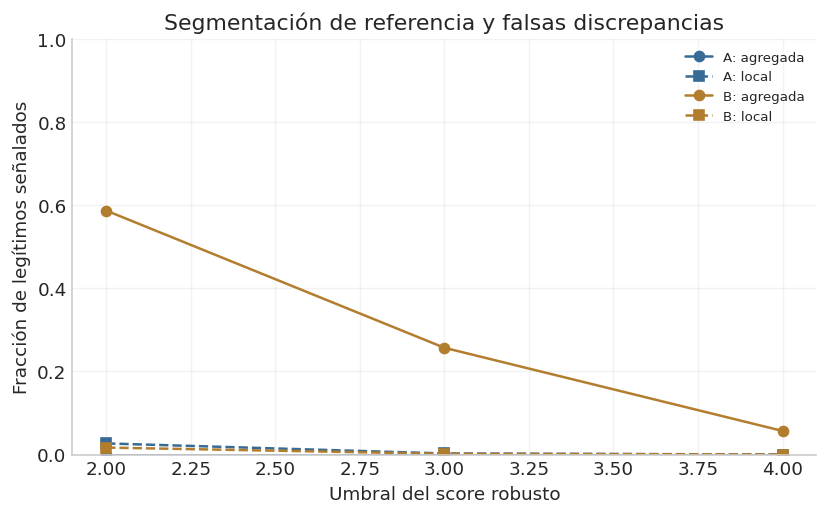

In [9]:
group_a=advanced_rng.normal(14.5,.15,1200)
group_b=advanced_rng.normal(15.2,.30,600)
pooled=np.r_[group_a,group_b]
threshold_rows=[]
for cutoff in [2.,3.,4.]:
    for name,values in [('A',group_a),('B',group_b)]:
        pooled_scores=np.array([robust_discrepancy(float(v),pooled)[0] for v in values])
        local_scores=np.array([robust_discrepancy(float(v),values)[0] for v in values])
        threshold_rows.append({'grupo':name,'umbral':cutoff,'alarma_referencia_agregada':np.mean(pooled_scores>cutoff),'alarma_referencia_local':np.mean(local_scores>cutoff)})
threshold_rows=pd.DataFrame(threshold_rows);display(threshold_rows)
fig,ax=plt.subplots()
for group,color in [('A',BLUE),('B',GOLD)]:
    part=threshold_rows[threshold_rows['grupo']==group]
    ax.plot(part['umbral'],part['alarma_referencia_agregada'],marker='o',color=color,label=f'{group}: agregada')
    ax.plot(part['umbral'],part['alarma_referencia_local'],marker='s',linestyle='--',color=color,label=f'{group}: local')
ax.set(xlabel='Umbral del score robusto',ylabel='Fracción de legítimos señalados',ylim=(0,1),title='Segmentación de referencia y falsas discrepancias');ax.legend(fontsize=8);plt.show()
advanced_metrics.update({'Ingreso conciliado por eventos (COP)':int(clean_result['income']),'Cambio de saldo consolidado (COP)':int(clean_result['balance_change']),'Duplicado contradictorio rechazado':conflict_rejected})

**Interpretación y uso.** Las referencias de este experimento se construyen con los propios grupos legítimos para aislar el efecto de mezcla; no se presenta como validación fuera de muestra. Una implementación debe estimar la referencia en entrenamiento y evaluar en un período posterior.

## Comprobaciones y límites

Las identidades y contraejemplos siguientes son parte del experimento; no verifican desempeño productivo.

In [10]:
assert gross==10_000_000 and eligible==3_000_000
assert np.allclose(conversions['mensual_COP'],3_000_000)
assert np.isfinite(robustness.select_dtypes('number')).all().all()

## Resultados computados

In [11]:
metrics = {'Abonos brutos (COP)': int(gross), 'Ingreso elegible (COP)': int(eligible), 'Sobreestimación por sumar abonos': round(float(gross/eligible),3), 'Conversiones reconciliadas': len(conversions)}
metrics.update(advanced_metrics)
print("LAB_METRICS:" + json.dumps(metrics, ensure_ascii=False))

LAB_METRICS:{"Abonos brutos (COP)": 10000000, "Ingreso elegible (COP)": 3000000, "Sobreestimación por sumar abonos": 3.333, "Conversiones reconciliadas": 5, "Ingreso conciliado por eventos (COP)": 3000000, "Cambio de saldo consolidado (COP)": 7000000, "Duplicado contradictorio rechazado": true}


## Ideas y preguntas para continuar

1. Añadir trazabilidad entre cuenta origen y destino para deduplicar traslados.
2. Conciliar ingreso bruto, neto y ventas de negocio por separado.
3. Repetir el experimento con grupos multimodales y escalas casi cero.
4. Cuantificar efecto de ruido OCR sin llamar fraude a un error de extracción.
5. Evaluar el costo de pedir soportes adicionales frente a la información que aportan.

## Fuentes y relación con el proyecto

Derivaciones y flujos sintéticos construidos dentro del notebook. Las conversiones declaran su convención; las categorías de flujo no proceden de clientes. Modelo de referencia del proyecto: `../README.md`.

Consultar también `../README.md` y `../../MODEL_AND_LOSS_METHODS.md`.

## Uso responsable y ficha mínima de salida

Antes de una aplicación institucional, registrar población, corte de información, versión del modelo, horizonte, unidades y cobertura de fuentes. Separar score de anomalía, probabilidad estimada y costo por acción. Una discrepancia o un desvío requiere evidencia independiente antes de llamarlo fraude. El experimento está completo en su alcance sintético; no sustituye calibración externa, integración de datos o validación independiente.

## Preguntas para refutar el desarrollo

1. ¿La mejora persiste al cambiar el mecanismo generador y la cohorte?
2. ¿Qué variable solo estaría disponible después de decidir?
3. ¿Cuánto del beneficio depende de una eficacia o cobertura supuesta?
4. ¿Qué caso legítimo produce la misma señal?
5. ¿Puede otra persona reconstruir el resultado desde las celdas y los parámetros?

## Diccionario de símbolos y unidades

| Símbolo | Significado en este notebook | Unidad o restricción |
|---|---|---|
| F, ΔB | Flujos firmados y cambio de saldo | COP; traslados internos cancelan |
| a, t | Disponibilidad del evento y corte | Días sintéticos |
| MAD | Mediana de desvíos absolutos | Escala de la referencia |
| z | Desviación robusta normalizada | No es probabilidad |
| n_min, s_min | Tamaño y escala mínimos | Reglas de cobertura |
| None | Abstención por referencia insuficiente | No convertirla automáticamente a cero |

## Modelos y casos de uso

| Modelo o técnica | Para qué usarlo | Condición para interpretar su salida |
|---|---|---|
| Conciliación por ID | Separar ingreso, traslado y financiación | Contradicciones generan excepción |
| Conversión temporal | Homogeneizar periodicidad de ingreso | Dos quincenas no equivalen a cada 14 días |
| Score mediana/MAD | Explorar discrepancia en una referencia | Contrastar contaminación y mezcla |
| Abstención | Evitar scores fabricados por escala cero | Definir verificación o revisión de calidad |

Referencias técnicas adicionales: [logit](https://scikit-learn.org/stable/modules/linear_model.html), [beta-binomial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.betabinom.html), [MILP](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html). Las distribuciones, datos y resultados de este notebook son sintéticos y se generan en las celdas.